# NB01 — Week 3: C-MAPSS Ingestion, RUL Labels & EDA
**Objective:** raw C-MAPSS-format text → typed DataFrame → RUL labels → DuckDB, plus first EDA plots.

Notebook-first rule: all logic lives HERE. In the conversion phase this notebook
promotes into `aip_data/cmapss.py` + `aip_data/synthetic.py` (reference modules
already exist in the repo as the conversion target).

**Interface contracts produced (frozen — see Phase 1 SOP §7.2):**
DuckDB tables `cycles(fd_set, split, unit_id, cycle, op1..3, s1..21, rul)` and `engines(...)`.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

DATA_DIR = Path("../../data")
USE_REAL = (DATA_DIR / "raw/cmapss/train_FD001.txt").exists()  # else synthetic
FD = "FD001" if USE_REAL else "FD00S"
RUL_CAP = 125
print(f"dataset mode: {'REAL ' + FD if USE_REAL else 'SYNTHETIC ' + FD}")

dataset mode: SYNTHETIC FD00S


## 1. Synthetic C-MAPSS-format generator (fallback + repeatable demos)
Power-law degradation per informative sensor; a fixed flat-sensor subset mimics
FD001's uninformative channels. Test units are truncated; true remaining life
goes to `RUL_*.txt` — byte-compatible with NASA's layout.

In [2]:
FLAT = {0, 4, 5, 9, 15, 17, 18}  # 0-based -> s1,s5,s6,s10,s16,s18,s19


def gen_synthetic(out_dir: Path, n_train=40, n_test=20, seed=7, fd="FD00S"):
    rng = np.random.default_rng(seed)
    out_dir.mkdir(parents=True, exist_ok=True)

    def unit_traj(life):
        frac = np.arange(1, life + 1) / life
        cols = []
        for j in range(21):
            base = 100.0 + 10 * j
            if j in FLAT:
                cols.append(base + rng.normal(0, 0.01, life))
            else:
                d = 1.0 if j % 2 == 0 else -1.0
                cols.append(base + d * rng.uniform(3, 8) * frac ** rng.uniform(1.2, 2.5)
                            + rng.normal(0, 0.15, life))
        return np.column_stack(cols)

    def write(n_units, truncate):
        rows, ruls = [], []
        for u in range(1, n_units + 1):
            life = int(rng.integers(140, 320))
            traj = unit_traj(life)
            ops = rng.normal([0, 0, 100], [0.002, 0.0003, 0.0], (life, 3))
            last = int(rng.integers(int(life * 0.4), life - 5)) if truncate else life
            if truncate:
                ruls.append(life - last)
            for c in range(last):
                vals = [u, c + 1, *ops[c], *traj[c]]
                rows.append(" ".join(f"{v:d}" if i < 2 else f"{v:.4f}"
                                     for i, v in enumerate(vals)) + " ")
        return rows, ruls

    tr, _ = write(n_train, False)
    te, ruls = write(n_test, True)
    (out_dir / f"train_{fd}.txt").write_text("\n".join(tr) + "\n")
    (out_dir / f"test_{fd}.txt").write_text("\n".join(te) + "\n")
    (out_dir / f"RUL_{fd}.txt").write_text("\n".join(map(str, ruls)) + "\n")
    return out_dir


if not USE_REAL:
    base = gen_synthetic(DATA_DIR / "synthetic/cmapss")
else:
    base = DATA_DIR / "raw/cmapss"
print("data at:", base)

data at: ..\..\data\synthetic\cmapss


## 2. Parser — 26 space-separated columns, trailing-space tolerant

In [3]:
OP = [f"op{i}" for i in range(1, 4)]
S = [f"s{i}" for i in range(1, 22)]
COLS = ["unit_id", "cycle", *OP, *S]


def parse_cmapss(path: Path) -> pl.DataFrame:
    df = pl.read_csv(path, separator=" ", has_header=False, truncate_ragged_lines=True,
                     new_columns=COLS,
                     schema_overrides={"unit_id": pl.Int32, "cycle": pl.Int32})
    return df.select(COLS).drop_nulls(subset=["unit_id", "cycle"])


train = parse_cmapss(base / f"train_{FD}.txt")
test = parse_cmapss(base / f"test_{FD}.txt")
print(train.shape, test.shape, "| units:", train["unit_id"].n_unique())
assert train.null_count().sum_horizontal().item() == 0

(8860, 26) (3061, 26) | units: 40


## 3. RUL labels
Train: `max_cycle − cycle`, capped at 125 (early-life degradation is unobservable —
an uncapped linear target teaches noise). Test: attach per-unit final RUL from
`RUL_*.txt`, back-propagate along cycles, same cap.

In [4]:
train = train.with_columns(
    (pl.col("cycle").max().over("unit_id") - pl.col("cycle"))
    .clip(upper_bound=RUL_CAP).alias("rul"))

final = pl.read_csv(base / f"RUL_{FD}.txt", has_header=False,
                    new_columns=["final_rul"]).with_row_index("idx")
final = final.with_columns((pl.col("idx") + 1).cast(pl.Int32).alias("unit_id"))
test = (test.join(final.select("unit_id", "final_rul"), on="unit_id", how="left")
        .with_columns((pl.col("cycle").max().over("unit_id") - pl.col("cycle")
                       + pl.col("final_rul")).clip(upper_bound=RUL_CAP).alias("rul"))
        .drop("final_rul"))

last = train.filter(pl.col("cycle") == pl.col("cycle").max().over("unit_id"))
assert (last["rul"] == 0).all(), "last train cycle must have RUL 0"
print("RUL label sanity OK — train max RUL:", train["rul"].max())

RUL label sanity OK — train max RUL: 125


## 4. DuckDB load (idempotent per fd_set/split) — the §7.2 frozen schema

In [5]:
con = duckdb.connect(str(DATA_DIR / "interim/nb_aip.duckdb"))
sensor_ddl = ", ".join(f"{c} DOUBLE" for c in [*OP, *S])
con.execute(f"""CREATE TABLE IF NOT EXISTS cycles (
    fd_set VARCHAR, split VARCHAR, unit_id INTEGER, cycle INTEGER,
    {sensor_ddl}, rul INTEGER)""")
con.execute("""CREATE TABLE IF NOT EXISTS engines (
    fd_set VARCHAR, split VARCHAR, unit_id INTEGER, max_cycle INTEGER)""")

for split, df in (("train", train), ("test", test)):
    con.execute("DELETE FROM cycles WHERE fd_set=? AND split=?", [FD, split])
    con.execute("DELETE FROM engines WHERE fd_set=? AND split=?", [FD, split])
    con.register("_in", df.with_columns(pl.lit(FD).alias("fd_set"),
                                        pl.lit(split).alias("split")).to_arrow())
    con.execute(f"""INSERT INTO cycles SELECT fd_set, split, unit_id, cycle,
                    {", ".join([*OP, *S])}, rul FROM _in""")
    con.execute("""INSERT INTO engines SELECT fd_set, split, unit_id, MAX(cycle)
                   FROM cycles WHERE fd_set=? AND split=? GROUP BY 1,2,3""",
                [FD, split])
    con.unregister("_in")

print(con.execute("SELECT fd_set, split, COUNT(*) n, COUNT(DISTINCT unit_id) units "
                  "FROM cycles GROUP BY 1,2").df())

  fd_set  split     n  units
0  FD00S  train  8860     40
1  FD00S   test  3061     20


## 5. EDA — lifetimes and sensor trajectories

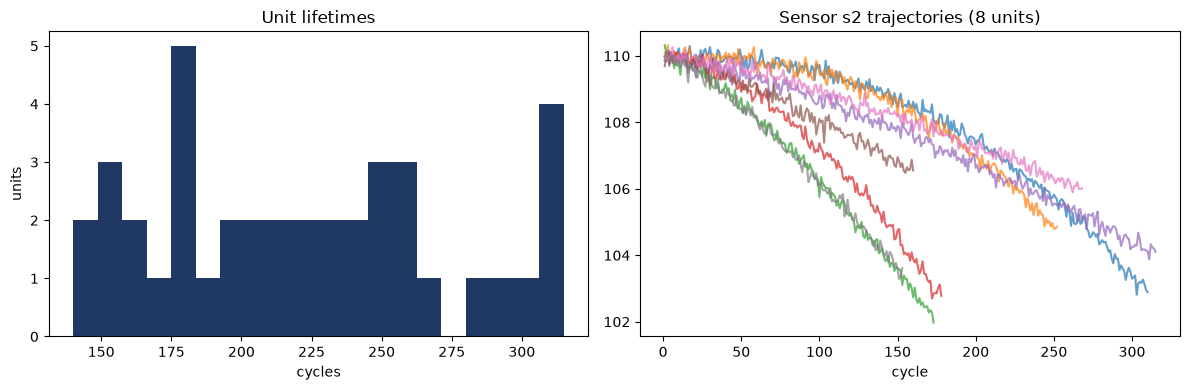

NB01 complete.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
lifetimes = train.group_by("unit_id").agg(pl.col("cycle").max())["cycle"]
axes[0].hist(lifetimes, bins=20, color="#1F3864")
axes[0].set(title="Unit lifetimes", xlabel="cycles", ylabel="units")
for u in train["unit_id"].unique().sort()[:8]:
    d = train.filter(pl.col("unit_id") == u)
    axes[1].plot(d["cycle"], d["s2"], alpha=0.7)
axes[1].set(title="Sensor s2 trajectories (8 units)", xlabel="cycle")
plt.tight_layout()
plt.savefig(DATA_DIR / "interim/nb01_eda.png", dpi=110)
plt.show()
print("NB01 complete.")